In [2]:
# Libraries used

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Brief Data Analysis

folder_path = "data/"
datasets = {}
summary_list = []

for file_name in os.listdir(folder_path):
    file_path = os.path.join(folder_path, file_name)
    table_name = file_name[:-4]

    df = pd.read_csv(file_path)
    datasets[table_name] = df
    
    row_count = df.shape[0]
    col_count = df.shape[1]
    
    total_cells = row_count * col_count
    missing_cells = df.isnull().sum().sum()
    missing_pct = (missing_cells / total_cells) * 100 if total_cells > 0 else 0
    
    memory_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
    
    summary_list.append({
        'Dataset': table_name,
        'Rows': row_count,
        'Columns': col_count,
        'Missing Data (%)': round(missing_pct, 2),
        'Memory (MB)': round(memory_mb, 2)
    })

summary_df = pd.DataFrame(summary_list)

summary_df_sorted = summary_df.sort_values(by='Rows', ascending=False).reset_index(drop=True)

print("=== Dataset Inventory & Size Summary ===")
print(summary_df_sorted.to_string())

=== Dataset Inventory & Size Summary ===
             Dataset   Rows  Columns  Missing Data (%)  Memory (MB)
0            Scoring  43848       31             34.14        17.89
1         TeamVsTeam  23862        8             10.28         4.46
2             Master   7469       31             38.76         6.59
3            Goalies   4096       23             30.76         1.26
4      AwardsPlayers   2021        6             22.46         0.50
5            Coaches   1741       14             21.00         0.46
6    ScoringShootout   1487        7              0.00         0.21
7              Teams   1459       27             21.73         0.72
8         TeamSplits   1459       43             33.24         0.60
9          TeamsPost    895       17             15.32         0.19
10        SeriesPost    802       13              8.02         0.30
11               HOF    356        4              0.00         0.06
12   GoaliesShootout    346        8              0.00         0.05
13     

Scoring: playerID,year,stint,tmID,lgID,pos,GP,G,A,Pts,PIM,+/-,PPG,PPA,SHG,SHA,GWG,GTG,SOG,PostGP,PostG,PostA,PostPts,PostPIM,Post+/-,PostPPG,PostPPA,PostSHG,PostSHA,PostGWG,PostSOG
TeamVsTeam: year,lgID,tmID,oppID,W,L,T,OTL
Master: playerID,coachID,hofID,firstName,lastName,nameNote,nameGiven,nameNick,height,weight,shootCatch,legendsID,ihdbID,hrefID,firstNHL,lastNHL,firstWHA,lastWHA,pos,birthYear,birthMon,birthDay,birthCountry,birthState,birthCity,deathYear,deathMon,deathDay,deathCountry,deathState,deathCity
Goalies: playerID,year,stint,tmID,lgID,GP,Min,W,L,T/OL,ENG,SHO,GA,SA,PostGP,PostMin,PostW,PostL,PostT,PostENG,PostSHO,PostGA,PostSA
AwardsPlayers: playerID,award,year,lgID,note,pos
Coaches: coachID,year,tmID,lgID,stint,notes,g,w,l,t,postg,postw,postl,postt
ScoringShootout: playerID,year,stint,tmID,S,G,GDG
Teams: year,lgID,tmID,franchID,confID,divID,rank,playoff,G,W,L,T,OTL,Pts,SoW,SoL,GF,GA,name,PIM,BenchMinor,PPG,PPC,SHA,PKG,PKC,SHF
TeamsSplit: year,lgID,tmID,hW,hL,hT,hOTL,rW,rL,rT,rOTL,SepW,SepL,SepT,SepOL,OctW,OctL,OctT,OctOL,NovW,NovL,NovT,NovOL,DecW,DecL,DecT,DecOL,JanW,JanL,JanT,JanOL,FebW,FebL,FebT,FebOL,MarW,MarL,MarT,MarOL,AprW,AprL,AprT,AprOL
TeamsPost: year,lgID,tmID,G,W,L,T,GF,GA,PIM,BenchMinor,PPG,PPC,SHA,PKG,PKC,SHF
SeriesPost: year,round,series,tmIDWinner,lgIDWinner,tmIDLoser,lgIDLoser,W,L,T,GoalsWinner,GoalsLoser,note
HOF: year,hofID,name,category
GoaliesShootout: playerID,year,stint,tmID,W,L,SA,GA
ScoringSC: playerID,year,tmID,lgID,pos,GP,G,A,Pts,PIM
ScoringSup: playerID,year,PPA,SHA
AwardsMisc: name,ID,award,year,lgID,note
AwardsCoaches: coachID,award,year,lgID,note

In [4]:
# Remove graphs not needed

datasets_to_remove = ["TeamsSC", "GoaliesSC", "TeamsHalf", "CombinedShutouts", "abbrev"]

for name in datasets_to_remove:
    datasets.pop(name)

In [5]:
# Analyse missing data on each column of each dataset

column_missing_summary = {}

for table_name, df in datasets.items():
    missing_count = df.isnull().sum()
    missing_pct = (df.isnull().mean() * 100).round(2)
    
    col_summary_df = pd.DataFrame({
        'Missing Count': missing_count,
        'Missing Percentage (%)': missing_pct
    })
    
    col_summary_filtered = col_summary_df[col_summary_df['Missing Count'] > 0]
    
    if not col_summary_filtered.empty:
        column_missing_summary[table_name] = col_summary_filtered
        
        print(f"=== Missing Data Breakdown: {table_name} ===")
        print(col_summary_filtered.to_string())
        print("\n" + "-" * 50 + "\n")
    else:
        print(f"=== Missing Data Breakdown: {table_name} ===")
        print("No missing data found in this dataset!\n")
        print("-" * 50 + "\n")

=== Missing Data Breakdown: AwardsCoaches ===
      Missing Count  Missing Percentage (%)
note             75                   100.0

--------------------------------------------------

=== Missing Data Breakdown: AwardsMisc ===
      Missing Count  Missing Percentage (%)
ID               37                   30.83
note            105                   87.50

--------------------------------------------------

=== Missing Data Breakdown: AwardsPlayers ===
      Missing Count  Missing Percentage (%)
note           1898                   93.91
pos             826                   40.87

--------------------------------------------------

=== Missing Data Breakdown: Coaches ===
       Missing Count  Missing Percentage (%)
notes           1730                   99.37
g                  1                    0.06
w                  1                    0.06
l                  1                    0.06
t                  1                    0.06
postg            846                   48.59

In [6]:
# Cleaning Data Implementation

# AwardsCoaches - Remove 'note' column
if 'AwardsCoaches' in datasets and 'note' in datasets['AwardsCoaches'].columns:
    datasets['AwardsCoaches'] = datasets['AwardsCoaches'].drop(columns=['note'])

# AwardsMisc - Remove 'note' column; Remove rows without 'ID'
if 'AwardsMisc' in datasets:
    df = datasets['AwardsMisc']
    if 'note' in df.columns:
        df = df.drop(columns=['note'])
    if 'ID' in df.columns:
        df = df.dropna(subset=['ID'])
    datasets['AwardsMisc'] = df

# AwardsPlayers - Remove 'note' and 'pos' columns
if 'AwardsPlayers' in datasets:
    df = datasets['AwardsPlayers']
    cols_to_drop = [col for col in ['note', 'pos'] if col in df.columns]
    datasets['AwardsPlayers'] = df.drop(columns=cols_to_drop)

# Coaches - Remove 'note' column; delete empty rows or those missing 'g', 'w', 'l', 't'; add 0 to empty 'post' columns
if 'Coaches' in datasets:
    df = datasets['Coaches']
    if 'note' in df.columns:
        df = df.drop(columns=['note'])
    essential_cols = [c for c in ['g', 'w', 'l', 't'] if c in df.columns]
    if essential_cols:
        df = df.dropna(subset=essential_cols)
    post_cols = [c for c in df.columns if c.startswith('post')]
    for col in post_cols:
        df.loc[:, col] = df[col].fillna(0)
    datasets['Coaches'] = df

# Goalies - Fill 0 for postseason stats; drop rows missing core identifiers (playerID or tmID)
if 'Goalies' in datasets:
    df = datasets['Goalies']
    post_cols_goalies = ['PostGP', 'PostMin', 'PostW', 'PostL', 'PostT', 'PostENG', 'PostSHO', 'PostGA', 'PostSA']
    for col in post_cols_goalies:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    id_cols = [c for c in ['playerID', 'tmID'] if c in df.columns]
    if id_cols:
        df = df.dropna(subset=id_cols)
    datasets['Goalies'] = df

# GoaliesShootout - Fill 0 for missing shootout stats (W, L, SA, GA); drop rows missing playerID or tmID
if 'GoaliesShootout' in datasets:
    df = datasets['GoaliesShootout']
    for col in ['W', 'L', 'SA', 'GA']:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    id_cols = [c for c in ['playerID', 'tmID'] if c in df.columns]
    if id_cols:
        df = df.dropna(subset=id_cols)
    datasets['GoaliesShootout'] = df

# HOF - Remove rows missing essential identifiers (hofID or name); standardize category classifications
if 'HOF' in datasets:
    df = datasets['HOF']
    id_cols = [c for c in ['hofID', 'name'] if c in df.columns]
    if id_cols:
        df = df.dropna(subset=id_cols)
    if 'category' in df.columns:
        df['category'] = df['category'].str.strip().str.title()
    datasets['HOF'] = df

# Master - Remove 'nameNote' column; drop rows missing primary player keys (playerID)
if 'Master' in datasets:
    df = datasets['Master']
    if 'nameNote' in df.columns:
        df = df.drop(columns=['nameNote'])
    if 'playerID' in df.columns:
        df = df.dropna(subset=['playerID'])
    datasets['Master'] = df

# Scoring - Fill 0 for specialty teams/postseason columns; drop rows missing playerID
if 'Scoring' in datasets:
    df = datasets['Scoring']
    scoring_fill_cols = ['+/-', 'PPG', 'PPA', 'SHG', 'SHA', 'GWG', 'GTG', 'SOG', 
                         'PostGP', 'PostG', 'PostA', 'PostPts', 'PostPIM', 'Post+/-', 
                         'PostPPG', 'PostPPA', 'PostSHG', 'PostSHA', 'PostGWG', 'PostSOG']
    for col in scoring_fill_cols:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    if 'playerID' in df.columns:
        df = df.dropna(subset=['playerID'])
    datasets['Scoring'] = df

# ScoringSC - Fill 0 for empty statistical columns (G, A, Pts, PIM) for Stanley Cup appearance players
if 'ScoringSC' in datasets:
    df = datasets['ScoringSC']
    for col in ['G', 'A', 'Pts', 'PIM']:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    datasets['ScoringSC'] = df

# ScoringShootout - Fill 0 for empty shootout goals (G) and GDG; ensure valid counts for attempts (S)
if 'ScoringShootout' in datasets:
    df = datasets['ScoringShootout']
    for col in ['G', 'GDG', 'S']:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    datasets['ScoringShootout'] = df

# ScoringSup - Fill 0 for missing supplemental power-play or short-handed assists (PPA, SHA)
if 'ScoringSup' in datasets:
    df = datasets['ScoringSup']
    for col in ['PPA', 'SHA']:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    datasets['ScoringSup'] = df

# SeriesPost - Remove 'note' column; drop rows missing series round, winner ID, or loser ID
if 'SeriesPost' in datasets:
    df = datasets['SeriesPost']
    if 'note' in df.columns:
        df = df.drop(columns=['note'])
    series_id_cols = [c for c in ['round', 'tmIDWinner', 'tmIDLoser'] if c in df.columns]
    if series_id_cols:
        df = df.dropna(subset=series_id_cols)
    datasets['SeriesPost'] = df

# Teams - Fill 0 for pre-shootout era SoW/SoL; ensure correct integer types for rank and Pts
if 'Teams' in datasets:
    df = datasets['Teams']
    for col in ['SoW', 'SoL']:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    for col in ['rank', 'Pts']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
    datasets['Teams'] = df

# TeamSplits - Fill 0 for unplayed splits; drop rows missing core identifiers (tmID or year)
if 'TeamSplits' in datasets:
    df = datasets['TeamSplits']
    numeric_cols = df.select_dtypes(include=['number']).columns
    df[numeric_cols] = df[numeric_cols].fillna(0)
    id_cols = [c for c in ['tmID', 'year'] if c in df.columns]
    if id_cols:
        df = df.dropna(subset=id_cols)
    datasets['TeamSplits'] = df

# TeamsPost - Fill 0 for postseason specialty stats; drop rows missing tmID or year
if 'TeamsPost' in datasets:
    df = datasets['TeamsPost']
    post_team_cols = ['BenchMinor', 'PPG', 'PPC', 'SHA', 'PKG', 'PKC', 'SHF']
    for col in post_team_cols:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    id_cols = [c for c in ['tmID', 'year'] if c in df.columns]
    if id_cols:
        df = df.dropna(subset=id_cols)
    datasets['TeamsPost'] = df

# TeamVsTeam - Fill 0 for missing head-to-head match stats (W, L, T, OTL); drop rows missing keys
if 'TeamVsTeam' in datasets:
    df = datasets['TeamVsTeam']
    for col in ['W', 'L', 'T', 'OTL']:
        if col in df.columns:
            df.loc[:, col] = df[col].fillna(0)
    id_cols = [c for c in ['tmID', 'oppID', 'year'] if c in df.columns]
    if id_cols:
        df = df.dropna(subset=id_cols)
    datasets['TeamVsTeam'] = df

print("=== Data Cleaning Complete: All datasets have been successfully processed and cleaned. ===")

=== Data Cleaning Complete: All datasets have been successfully processed and cleaned. ===


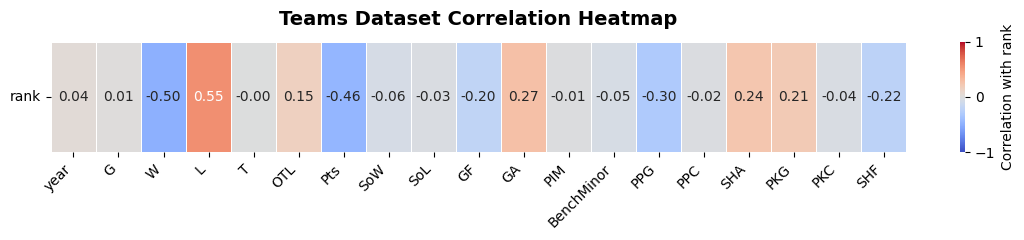

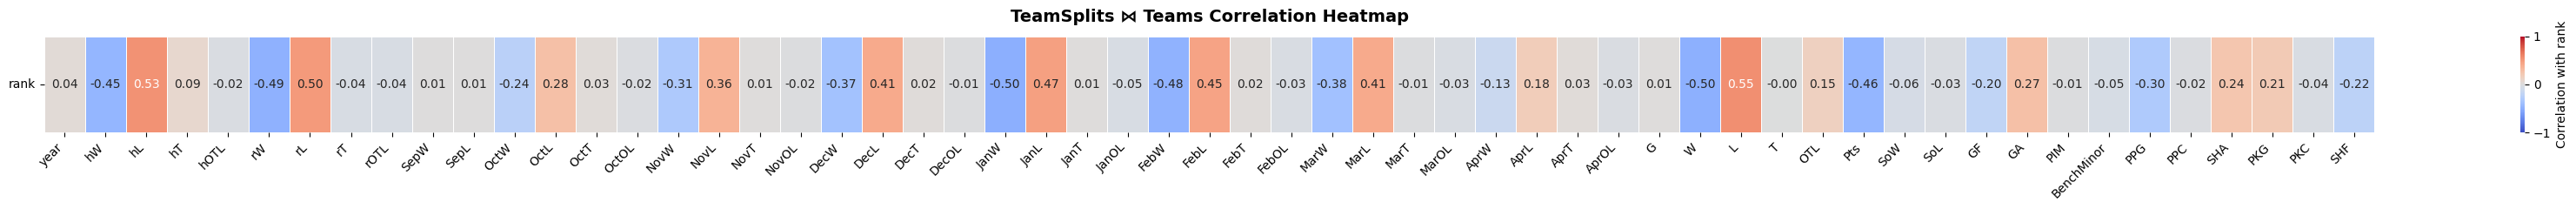

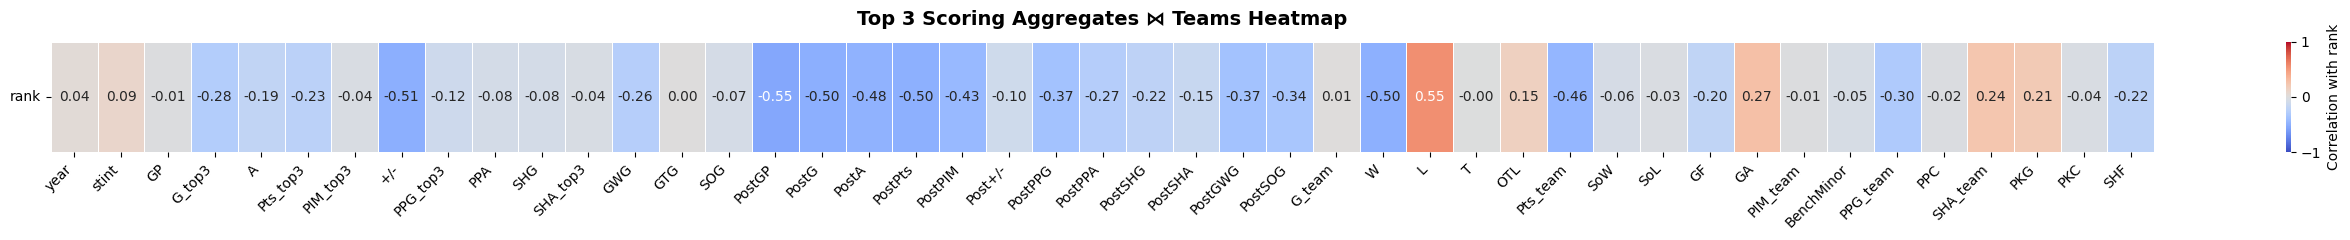

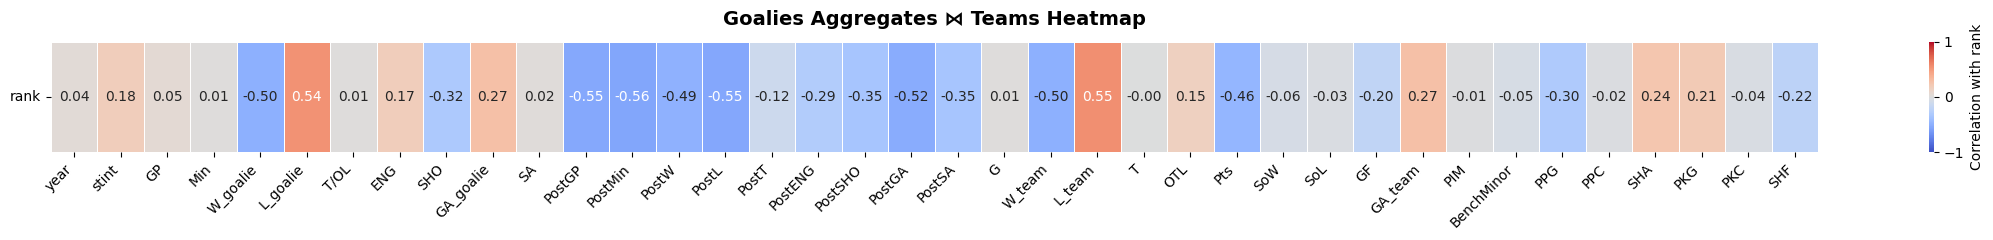

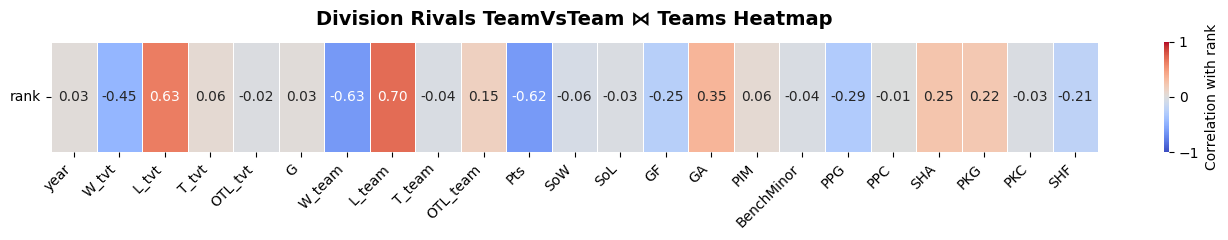

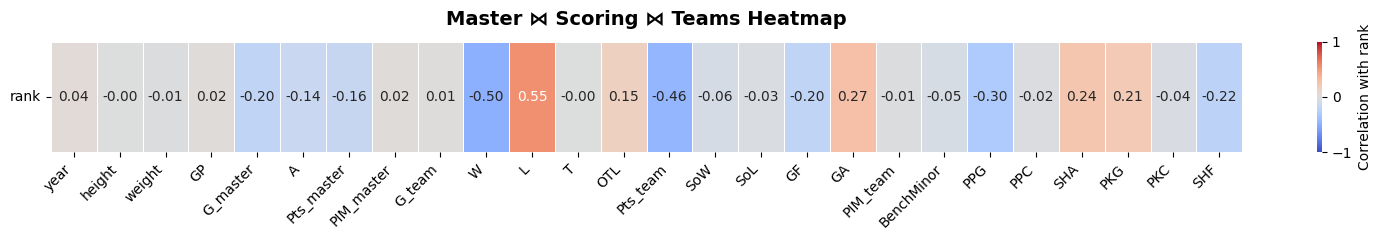

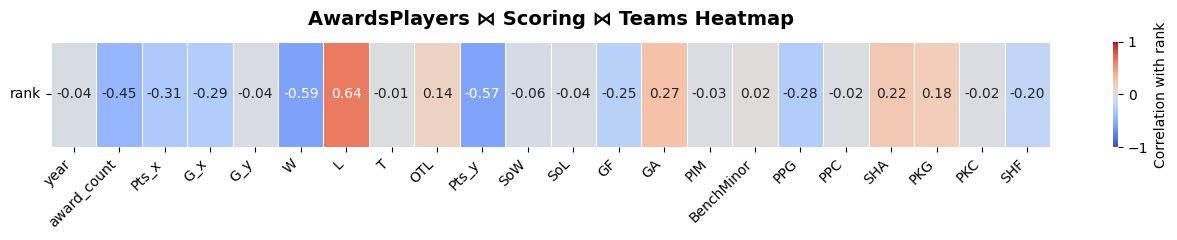

In [7]:
def plot_correlation_heatmap(df, title, figsize=None):
    """Plot a single heatmap row with correlations against Teams.rank."""
    numeric_df = df.select_dtypes(include=[np.number])

    if 'rank' not in numeric_df.columns:
        print(f"Skipping heatmap for {title}: 'rank' column not found.")
        return

    # Correlate every numeric field with rank
    corr = numeric_df.corr()['rank'].drop('rank', errors='ignore')
    corr = corr.dropna()

    if corr.empty:
        print(f"Skipping heatmap for {title}: No valid correlations.")
        return

    # One row only
    heatmap_data = pd.DataFrame([corr.values], columns=corr.index, index=['rank'])

    if figsize is None:
        figsize = (max(10, len(corr) * 0.6), 2.5)

    plt.figure(figsize=figsize)
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        center=0,
        linewidths=0.5,
        cbar_kws={'label': 'Correlation with rank'}
    )

    plt.title(title, fontsize=14, fontweight='bold', pad=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ==========================================
# 1. Teams (No join required)
# ==========================================
if 'Teams' in datasets:
    plot_correlation_heatmap(datasets['Teams'], "Teams Dataset Correlation Heatmap")

# ==========================================
# 2. TeamSplit ⋈ Teams (Join: tmID + year)
# ==========================================
if 'TeamSplits' in datasets and 'Teams' in datasets:
    teams_split_joined = pd.merge(datasets['TeamSplits'], datasets['Teams'], on=['tmID', 'year'], how='inner', suffixes=('_split', '_team'))
    plot_correlation_heatmap(teams_split_joined, "TeamSplits ⋈ Teams Correlation Heatmap")

# ==========================================
# 3. Scoring ⋈ Teams (Top 3 sum scoring per tmID + year, join to Teams)
# ==========================================
if 'Scoring' in datasets and 'Teams' in datasets:
    scoring_df = datasets['Scoring'].copy()
    # Sort by Pts (or G) descending and take top 3 per tmID and year
    if 'Pts' in scoring_df.columns:
        scoring_top3 = scoring_df.sort_values(by=['tmID', 'year', 'Pts'], ascending=[True, True, False])
        scoring_top3 = scoring_top3.groupby(['tmID', 'year']).head(3)
        scoring_agg = scoring_top3.groupby(['tmID', 'year']).sum(numeric_only=True).reset_index()
        
        scoring_teams_joined = pd.merge(scoring_agg, datasets['Teams'], on=['tmID', 'year'], how='inner', suffixes=('_top3', '_team'))
        plot_correlation_heatmap(scoring_teams_joined, "Top 3 Scoring Aggregates ⋈ Teams Heatmap")

# ==========================================
# 4. Goalies ⋈ Teams (Group Goalies by tmID + year, join to Teams)
# ==========================================
if 'Goalies' in datasets and 'Teams' in datasets:
    goalies_agg = datasets['Goalies'].groupby(['tmID', 'year']).sum(numeric_only=True).reset_index()
    goalies_teams_joined = pd.merge(goalies_agg, datasets['Teams'], on=['tmID', 'year'], how='inner', suffixes=('_goalie', '_team'))
    plot_correlation_heatmap(goalies_teams_joined, "Goalies Aggregates ⋈ Teams Heatmap")

# ==========================================
# 5. TeamVsTeam ⋈ Teams (Division rivals, aggregate by tmID + year, join to Teams)
# ==========================================
if 'TeamVsTeam' in datasets and 'Teams' in datasets:
    tvt = datasets['TeamVsTeam']
    teams_subset = datasets['Teams'][['tmID', 'year', 'divID']].drop_duplicates()
    
    # Merge division info for team and opponent
    tvt_div = tvt.merge(teams_subset, left_on=['tmID', 'year'], right_on=['tmID', 'year'], how='inner')
    tvt_div = tvt_div.rename(columns={'divID': 'divID_tm'})
    tvt_div = tvt_div.merge(teams_subset, left_on=['oppID', 'year'], right_on=['tmID', 'year'], suffixes=('', '_opp'), how='inner')
    tvt_div = tvt_div.rename(columns={'divID': 'divID_opp', 'tmID_x': 'tmID'})
    
    # Filter for division rivals (same division, different team)
    div_rivals = tvt_div[(tvt_div['divID_tm'] == tvt_div['divID_opp']) & (tvt_div['tmID'] != tvt_div['oppID'])]
    
    tvt_agg = div_rivals.groupby(['tmID', 'year']).sum(numeric_only=True).reset_index()
    tvt_teams_joined = pd.merge(tvt_agg, datasets['Teams'], on=['tmID', 'year'], how='inner', suffixes=('_tvt', '_team'))
    plot_correlation_heatmap(tvt_teams_joined, "Division Rivals TeamVsTeam ⋈ Teams Heatmap")

# ==========================================
# 6 & 7. Master ⋈ Scoring ⋈ Teams (Join on playerID, aggregate by tmID + year)
# ==========================================
if 'Master' in datasets and 'Scoring' in datasets and 'Teams' in datasets:
    master_scoring = pd.merge(datasets['Master'], datasets['Scoring'], on='playerID', how='inner')
    master_scoring_agg = master_scoring.groupby(['tmID', 'year']).agg({
        'height': 'mean',
        'weight': 'mean',
        'GP': 'sum',
        'G': 'sum',
        'A': 'sum',
        'Pts': 'sum',
        'PIM': 'sum'
    }).reset_index()
    
    master_scoring_teams = pd.merge(master_scoring_agg, datasets['Teams'], on=['tmID', 'year'], how='inner', suffixes=('_master', '_team'))
    plot_correlation_heatmap(master_scoring_teams, "Master ⋈ Scoring ⋈ Teams Heatmap")

# ==========================================
# 8. AwardsPlayers ⋈ Scoring ⋈ Teams (Join on playerID, group by tmID + year)
# ==========================================
if 'AwardsPlayers' in datasets and 'Scoring' in datasets and 'Teams' in datasets:
    awards_scoring = pd.merge(datasets['AwardsPlayers'], datasets['Scoring'], on=['playerID', 'year'], how='inner')
    awards_scoring_agg = awards_scoring.groupby(['tmID', 'year']).agg({
        'playerID': 'count', # Count awards won per team/year
        'Pts': 'sum',
        'G': 'sum'
    }).rename(columns={'playerID': 'award_count'}).reset_index()
    
    awards_teams_joined = pd.merge(awards_scoring_agg, datasets['Teams'], on=['tmID', 'year'], how='inner')
    plot_correlation_heatmap(awards_teams_joined, "AwardsPlayers ⋈ Scoring ⋈ Teams Heatmap")

In [13]:
# Predict team ranking for 2009 using only historical data.
# Preferred training seasons: 2000-2008.
# If any season from 2000-2008 is missing, extend the start to 1999.
# The feature for a season is the team's Win_Loss_Ratio from its previous season.

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

teams = datasets["Teams"].copy()

# Calculate the requested ratio.
teams["Win_Loss_Ratio"] = (
    teams["W"] / (teams["W"] + teams["L"] + teams["OTL"])
)

# Keep each team's previous-season ratio as the predictor.
teams = teams.sort_values(["lgID", "tmID", "year"])
teams["Previous_Win_Loss_Ratio"] = (
    teams.groupby(["lgID", "tmID"])["Win_Loss_Ratio"].shift(1)
)

available_seasons = set(teams["year"].unique())
preferred_seasons = set(range(2000, 2009))
missing_seasons = sorted(preferred_seasons - available_seasons)

if missing_seasons:
    train_start = 1999
    print(
        f"Missing season(s) in 2000-2008: {missing_seasons}. "
        "Extending the training period to start in 1999."
    )
else:
    train_start = 2000

# Training target seasons are the available seasons from train_start through 2008.
# Test only on 2009. No data from 2010 onward is used.
train = teams[
    (teams["year"] >= train_start) &
    (teams["year"] <= 2008) &
    (teams["Previous_Win_Loss_Ratio"].notna())
].copy()

test = teams[
    (teams["year"] == 2009) &
    (teams["Previous_Win_Loss_Ratio"].notna())
].copy()

if train.empty:
    raise ValueError(
        f"No training rows found for {train_start}-2008 after creating the previous-season feature."
    )
if test.empty:
    raise ValueError(
        "No test rows found for 2009. Check that the dataset contains 2009 and that those teams "
        "have a previous-season record."
    )

X_train = train[["Previous_Win_Loss_Ratio"]]
y_train = train["rank"]
X_test = test[["Previous_Win_Loss_Ratio"]]
y_test = test["rank"]

model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)
model.fit(X_train, y_train)

test["Predicted_Rank"] = model.predict(X_test)

mae = mean_absolute_error(y_test, test["Predicted_Rank"])
rmse = np.sqrt(mean_squared_error(y_test, test["Predicted_Rank"]))

print(f"Training target seasons: {train_start}-2008")
print(f"Training rows: {len(train)}")
print(f"Test season: 2009")
print(f"Test rows: {len(test)}")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

# Compare actual and predicted rankings for 2009.
display(
    test[[
        "year", "lgID", "tmID", "Previous_Win_Loss_Ratio",
        "rank", "Predicted_Rank"
    ]].sort_values(["lgID", "Predicted_Rank"])
)

# Exact ranking accuracy (round predicted ranks to nearest integer)
exact_accuracy = (
    test["Predicted_Rank"].round().astype(int) == test["rank"]
).mean() * 100

# Accuracy within one ranking position
within_one = (
    (test["Predicted_Rank"] - test["rank"]).abs() <= 1
).mean() * 100


Missing season(s) in 2000-2008: [2004]. Extending the training period to start in 1999.
Training target seasons: 1999-2008
Training rows: 237
Test season: 2009
Test rows: 30
MAE: 1.251
RMSE: 1.472


,year,lgID,tmID,Previous_Win_Loss_Ratio,rank,Predicted_Rank
1433,2009,NHL,CAL,0.560976,3,1.603331
1436,2009,NHL,CHI,0.560976,1,1.603331
1439,2009,NHL,DET,0.621951,2,1.892918
1446,2009,NHL,NJD,0.621951,1,1.892918
1458,2009,NHL,WAS,0.609756,1,2.408746
1429,2009,NHL,AND,0.512195,4,2.740498
1448,2009,NHL,NYR,0.524390,4,2.864470
1432,2009,NHL,BUF,0.500000,1,3.097468
1435,2009,NHL,CBS,0.500000,5,3.097468
1441,2009,NHL,FLO,0.500000,5,3.097468
